In [1]:
#import libraries
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

#load dataset
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [2]:
top_countries = df['job_country'].value_counts().head(6).index
top_countries

Index(['United States', 'India', 'United Kingdom', 'France', 'Germany',
       'Spain'],
      dtype='str', name='job_country')

In [10]:
df_job_country_salary = df.pivot_table(
    values='salary_year_avg',
    index='job_country',
    columns='job_title_short',
    aggfunc='median'
)

In [13]:
df_job_country_salary = df_job_country_salary.loc[top_countries]

job_list=['Data Analyst', 'Senior Data Analyst', 'Software Engineer']

df_job_country_salary = df_job_country_salary[job_list]

df_job_country_salary

job_title_short,Data Analyst,Senior Data Analyst,Software Engineer
job_country,,,
United States,90000.0,110000.0,130000.0
India,100500.0,111175.0,79200.0
United Kingdom,87750.0,111175.0,89100.0
France,69175.0,111175.0,142500.0
Germany,103750.0,111175.0,84975.0
Spain,91977.0,111175.0,77050.0


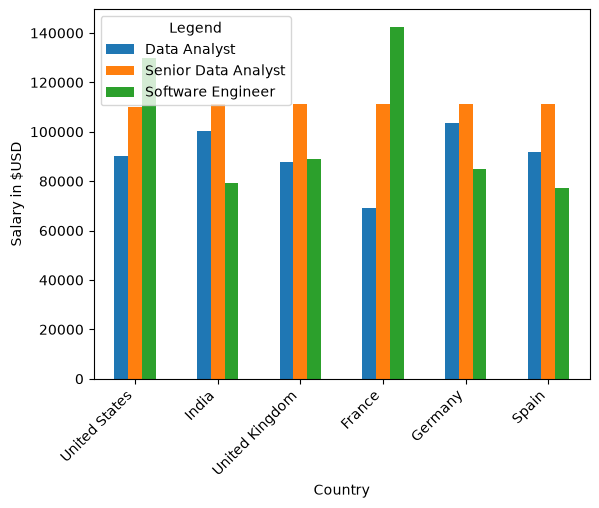

In [14]:
df_job_country_salary.plot(kind='bar')
plt.legend(title='Legend')
plt.xlabel('Country')
plt.ylabel('Salary in $USD')
plt.xticks(rotation=45, ha='right')
plt.show()